In [1]:
import os

import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt

In [2]:
DB_PTH = "people_detection.db"

In [3]:
conn = sqlite3.connect(DB_PTH)

In [4]:
df = pd.read_sql_query("SELECT COUNT(*) from boxes;", conn)
print(f"number of bounding boxes:\n{df}")

number of bounding boxes:
    COUNT(*)
0  115343867


In [5]:
df = pd.read_sql_query("SELECT COUNT(DISTINCT seq_path) FROM boxes;", conn)
print(f"number of unique seq file paths:\n{df}")

number of unique seq file paths:
   COUNT(DISTINCT seq_path)
0                      9634


In [6]:
df = pd.read_sql_query("SELECT COUNT(DISTINCT avi_path) FROM boxes;", conn)
print(f"number of unique avi file paths:\n{df}")

number of unique avi file paths:
   COUNT(DISTINCT avi_path)
0                      9634


In [7]:
df = pd.read_sql_query("SELECT COUNT(DISTINCT seq_name) FROM boxes;", conn)
print(f"number of unique seq names:\n{df}")

number of unique seq names:
   COUNT(DISTINCT seq_name)
0                      9634


In [10]:
df = pd.read_sql_query(
    """SELECT COUNT(*) AS unique_pairs_count
    FROM (
        SELECT DISTINCT seq_path, avi_path
        FROM boxes
    ) AS distinct_pairs;
    """, conn)
print(f"number of unique pairs of seq path and avi path:\n{df}")

number of unique pairs of seq path and avi path:
   unique_pairs_count
0                9634


In [36]:
df = pd.read_sql_query(
    """SELECT COUNT(*) AS unique_pairs_count
    FROM (
        SELECT DISTINCT seq_name, frame_n
        FROM boxes
    ) AS distinct_pairs;
    """, conn)
print(f"number of unique frames:\n{df}")

number of unique frames:
   unique_pairs_count
0            18704571


In [3]:
df = pd.read_sql_query(
    """SELECT COUNT(*) AS unique_pairs_count
    FROM (
        SELECT DISTINCT seq_name, track_id
        FROM boxes
    ) AS distinct_pairs;
    """, conn)
print(f"number of unique tracks:\n{df}")

number of unique tracks:
   unique_pairs_count
0               65567


In [24]:
def map_camera_type(x):
    if x in ["SPCA2093", "SunPlusLegacyCamera", "SunPlus_PG1_Camera1", "SunPlus_PG1_Camera2", "SunPlus_PG_Camera"]:
        return "cam1"
    elif x in ["SPCA2281B-L0"]:
        return "cam2"
    elif x in ["SPCA2281B-L1"]:
        return "cam3"
    else:
        return "unknow"

In [25]:
df = pd.read_sql_query(
    """SELECT camera_type, COUNT(*) AS value_count
    FROM boxes
    GROUP BY camera_type;
    """, conn)

df["camera_type"] = df["camera_type"].apply(map_camera_type)
df = df.groupby("camera_type").sum().reset_index()

df

,camera_type,value_count
0,cam1,108523393
1,cam2,558017
2,cam3,1210911
3,unknow,5051546


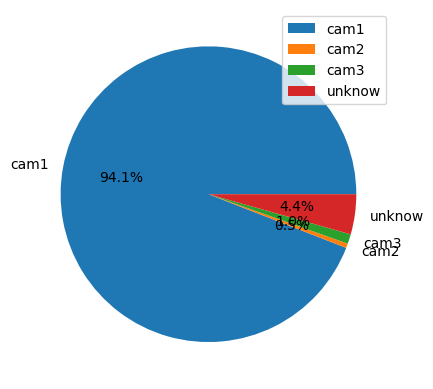

In [26]:
fig, ax = plt.subplots()
ax.pie(df["value_count"].values, labels=df["camera_type"].values, autopct='%1.1f%%');
plt.legend()

In [27]:
df = pd.read_sql_query(
    """SELECT camera_type, COUNT(DISTINCT seq_name) AS value_count
    FROM boxes
    GROUP BY camera_type;
    """, conn)

df["camera_type"] = df["camera_type"].apply(map_camera_type)
df = df.groupby("camera_type").sum().reset_index()

df

,camera_type,value_count
0,cam1,8250
1,cam2,82
2,cam3,108
3,unknow,1194


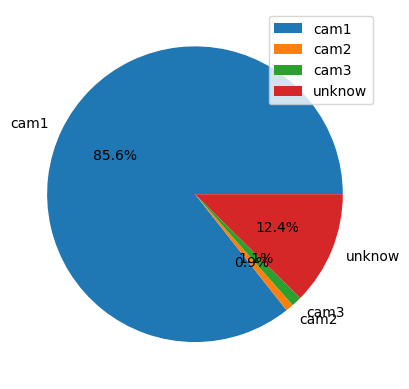

In [28]:
fig, ax = plt.subplots()
ax.pie(df["value_count"].values, labels=df["camera_type"].values, autopct='%1.1f%%');
plt.legend()

In [29]:
df = pd.read_sql_query(
    """SELECT DISTINCT seq_name, altitude
    FROM boxes;
    """, conn)

In [ ]:
df = pd.read_sql_query(
    """SELECT DISTINCT seq_name, altitude
    FROM boxes;
    """, conn)

In [ ]:
df[df["altitude"] == "NODATA"]

,seq_name,altitude
2327,Noise_1_middle_NoSw_28_17_23_38_2015.avi.seq,NODATA
2839,SaveVideo_Sun_Jan_17_09_45_21_2016.avi.seq,NODATA


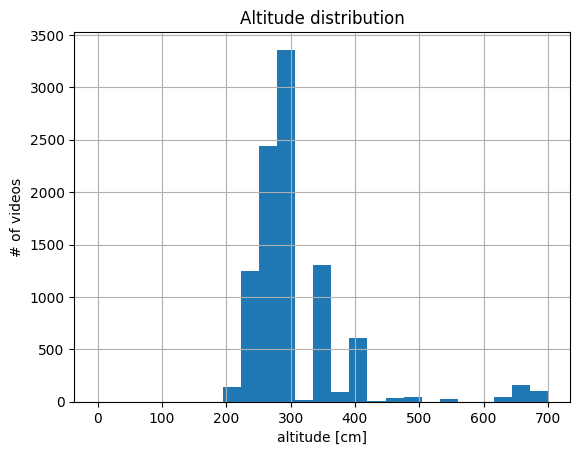

In [ ]:
df = df[~(df["altitude"] == "NODATA")]

plt.hist(df["altitude"].values, bins=25);
plt.grid()
plt.xlabel('altitude [cm]')
plt.ylabel('# of videos')
plt.title('Altitude distribution');

(18704571, 3)


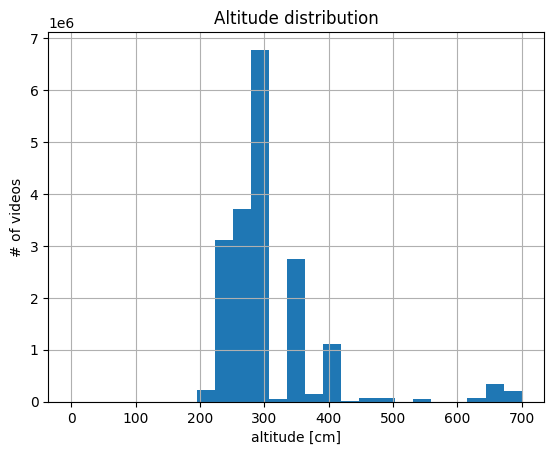

In [38]:
df = pd.read_sql_query(
    """SELECT DISTINCT seq_name, frame_n, altitude
    FROM boxes;
    """, conn)

print(df.shape)
df = df[~(df["altitude"] == "NODATA")]

plt.hist(df["altitude"].values, bins=25);
plt.grid()
plt.xlabel('altitude [cm]')
plt.ylabel('# of videos')
plt.title('Altitude distribution');

In [39]:
df = pd.read_sql_query(
    """SELECT DISTINCT seq_name, seq_path, avi_path
    FROM boxes;
    """, conn)

In [41]:
df_dedup = pd.read_csv("tmp/data_deduplicated.csv")
df_dedup.shape

(21585, 5)

In [43]:
df_tmp = pd.merge(
    df,
    df_dedup,
    how="left",
    on="seq_name"
)

In [45]:
df_tmp["is_algo_test"].value_counts()

is_algo_test
False    9157
True      477
Name: count, dtype: int64

In [46]:
df_tmp["vlc"].value_counts()

vlc
False    8755
True      879
Name: count, dtype: int64